DATASET INFORMATION
Dataset shape: (2000, 13)
Number of records: 2000
Number of input features: 12

First five rows:
   age    income  credit_score   loan_amount  loan_term  employment_years  \
0   59   45426.0         527.0  40134.134469         24              28.0   
1   49   37772.0         401.0  44205.463282         36               2.0   
2   35  123754.0         716.0  61620.350552         24              25.0   
3   63   23712.0         515.0  25648.428084         60              13.0   
4   28   21367.0         706.0  39032.375343         36              24.0   

   previous_defaults employment_type marital_status    education  \
0                  0        Contract       Divorced  High School   
1                  0        Salaried       Divorced  High School   
2                  0        Business       Divorced  High School   
3                  2        Salaried        Married     Graduate   
4                  1        Salaried       Divorced     Graduate   

   loan_def

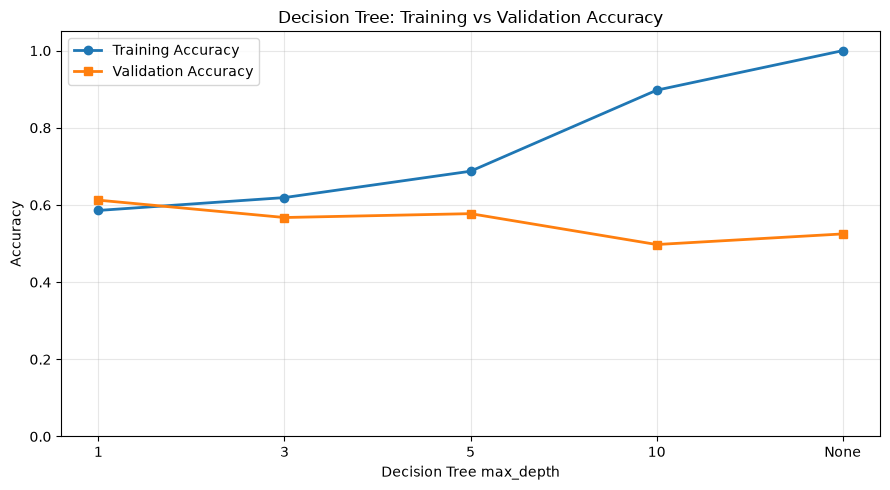


OVERFITTING EXPLANATION:

1. A shallow tree may underfit because it cannot learn enough patterns.
2. As tree depth increases, training accuracy may improve.
3. If training accuracy is much higher than validation accuracy,
   the model may be memorizing training examples.
4. Validation accuracy helps identify a model that generalizes better.


LOGISTIC REGRESSION 5-FOLD CROSS-VALIDATION
5-fold CV scores: [0.6958 0.6292 0.6583 0.625  0.5875]
CV mean accuracy: 0.6392
CV standard deviation: 0.0362
Final CV result: 0.6392 +/- 0.0362
Logistic Regression validation accuracy: 0.6550

DATA LEAKAGE DEMONSTRATION

METHOD 1: INCORRECT SCALING
Imputer and scaler fitted on the entire dataset.
Full dataset mean (first feature): 42.694

METHOD 2: CORRECT SCALING
Imputer and scaler fitted only on training data.
Training data mean (first feature): 42.605

DATA LEAKAGE COMPARISON
Incorrect scaling mean: 42.694
Correct scaling mean: 42.605

DATA LEAKAGE EXPLANATION (4 LINES):

1. Data leakage happens whe

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer

np.random.seed(42)
n = 2000

age = np.random.randint(21, 65, n)
income = np.random.randint(20000, 150001, n)
credit_score = np.random.randint(300, 851, n)
loan_term = np.random.choice([12, 24, 36, 48, 60], n)
employment_years = np.random.randint(0, 31, n)

previous_defaults = np.random.choice(
    [0, 1, 2, 3], n, p=[0.72, 0.18, 0.07, 0.03]
)

employment_type = np.random.choice(
    ["Salaried", "Self-employed", "Business", "Contract"], n
)

marital_status = np.random.choice(
    ["Single", "Married", "Divorced"], n
)

education = np.random.choice(
    ["High School", "Graduate", "Postgraduate"], n
)

application_date = pd.to_datetime(
    np.random.choice(
        pd.date_range("2022-01-01", "2025-12-31"), n
    )
)

loan_amount = (
    income * np.random.uniform(0.25, 1.15, n)
    + (credit_score - 300) * 35
    + loan_term * 180
    + np.random.normal(0, 5000, n)
)

loan_amount = np.clip(loan_amount, 5000, 200000)

risk_score = (
    -0.0035 * (credit_score - 600)
    + 0.000012 * (loan_amount - 50000)
    + 0.55 * previous_defaults
    - 0.025 * employment_years
    + np.random.normal(0, 0.45, n)
)

default_probability = 1 / (1 + np.exp(-risk_score))
loan_default = np.random.binomial(1, default_probability)

data = pd.DataFrame({
    "age": age,
    "income": income,
    "credit_score": credit_score,
    "loan_amount": loan_amount,
    "loan_term": loan_term,
    "employment_years": employment_years,
    "previous_defaults": previous_defaults,
    "employment_type": employment_type,
    "marital_status": marital_status,
    "education": education,
    "application_date": application_date,
    "loan_default": loan_default
})

data["application_month"] = data["application_date"].dt.month
data["application_year"] = data["application_date"].dt.year

data = data.drop(columns=["application_date"])

for column in [
    "income",
    "credit_score",
    "employment_years",
    "employment_type"
]:
    missing_indices = data.sample(
        frac=0.03, random_state=42
    ).index

    data.loc[missing_indices, column] = np.nan

TARGET = "loan_default"

X = data.drop(columns=[TARGET])
y = data[TARGET]

print("DATASET INFORMATION")
print("Dataset shape:", data.shape)
print("Number of records:", len(data))
print("Number of input features:", X.shape[1])

print("\nFirst five rows:")
print(data.head())

print("\nTarget distribution:")
print(y.value_counts())

print("\nMissing values:")
print(data.isnull().sum())

X_numeric = X.select_dtypes(include=np.number).copy()

print("\nNumeric features:", X_numeric.shape[1])

print("\nDATA SPLITTING")

X_train, X_temp, y_train, y_temp = train_test_split(
    X_numeric,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nValidation target distribution:")
print(y_val.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nTest set is kept aside for final evaluation.")

print("\nDECISION TREE OVERFITTING")

depth_values = [1, 3, 5, 10, None]

train_accuracies = []
validation_accuracies = []

tree_imputer = SimpleImputer(strategy="median")

X_train_filled = tree_imputer.fit_transform(X_train)
X_val_filled = tree_imputer.transform(X_val)

for depth in depth_values:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train_filled, y_train)

    train_predictions = tree.predict(X_train_filled)
    val_predictions = tree.predict(X_val_filled)

    train_acc = accuracy_score(y_train, train_predictions)
    val_acc = accuracy_score(y_val, val_predictions)

    train_accuracies.append(train_acc)
    validation_accuracies.append(val_acc)

    print(
        f"Depth {depth}: "
        f"Train Accuracy = {train_acc:.4f}, "
        f"Validation Accuracy = {val_acc:.4f}"
    )

depth_labels = ["1", "3", "5", "10", "None"]

plt.figure(figsize=(9, 5))

plt.plot(
    depth_labels,
    train_accuracies,
    marker="o",
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    depth_labels,
    validation_accuracies,
    marker="s",
    linewidth=2,
    label="Validation Accuracy"
)

plt.xlabel("Decision Tree max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Training vs Validation Accuracy")

plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "task1_overfitting.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("""
OVERFITTING EXPLANATION:

1. A shallow tree may underfit because it cannot learn enough patterns.
2. As tree depth increases, training accuracy may improve.
3. If training accuracy is much higher than validation accuracy,
   the model may be memorizing training examples.
4. Validation accuracy helps identify a model that generalizes better.
""")

print("\nLOGISTIC REGRESSION 5-FOLD CROSS-VALIDATION")

logistic_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=3000))
])

cv_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("5-fold CV scores:", np.round(cv_scores, 4))
print("CV mean accuracy: {:.4f}".format(cv_scores.mean()))

print(
    "CV standard deviation: {:.4f}".format(
        cv_scores.std()
    )
)

print(
    "Final CV result: {:.4f} +/- {:.4f}".format(
        cv_scores.mean(),
        cv_scores.std()
    )
)

logistic_pipeline.fit(X_train, y_train)

val_predictions = logistic_pipeline.predict(X_val)
val_accuracy = accuracy_score(y_val, val_predictions)

print(
    "Logistic Regression validation accuracy: {:.4f}".format(
        val_accuracy
    )
)

print("\nDATA LEAKAGE DEMONSTRATION")

wrong_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

wrong_pipeline.fit(X_numeric)

wrong_scaler = wrong_pipeline.named_steps["scaler"]

print("\nMETHOD 1: INCORRECT SCALING")
print("Imputer and scaler fitted on the entire dataset.")

print(
    "Full dataset mean (first feature):",
    round(wrong_scaler.mean_[0], 4)
)

correct_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

correct_pipeline.fit(X_train)

correct_scaler = correct_pipeline.named_steps["scaler"]

print("\nMETHOD 2: CORRECT SCALING")
print("Imputer and scaler fitted only on training data.")

print(
    "Training data mean (first feature):",
    round(correct_scaler.mean_[0], 4)
)

print("\nDATA LEAKAGE COMPARISON")

print(
    "Incorrect scaling mean:",
    round(wrong_scaler.mean_[0], 4)
)

print(
    "Correct scaling mean:",
    round(correct_scaler.mean_[0], 4)
)

print("""
DATA LEAKAGE EXPLANATION (4 LINES):

1. Data leakage happens when information from validation or test data enters training.
2. Incorrect scaling fits preprocessing using the entire dataset.
3. Correct scaling fits preprocessing only on the training dataset.
4. Pipelines prevent leakage by fitting preprocessing separately inside each CV fold.
""")

print("\nSUPERVISED VS UNSUPERVISED LEARNING")

problem_types = pd.DataFrame({
    "Problem": [
        "Spam detection",
        "Customer segmentation",
        "House price prediction",
        "Anomaly detection"
    ],
    "Learning Type": [
        "Supervised",
        "Unsupervised",
        "Supervised",
        "Usually Unsupervised"
    ],
    "Reason": [
        "Uses labelled spam/not-spam examples.",
        "Groups customers without predefined labels.",
        "Learns from houses with known prices.",
        "Often identifies unusual patterns without labels."
    ]
})

print(problem_types.to_string(index=False))

print("\nMACHINE LEARNING WORKFLOW")

workflow = [
    "1. Define the problem",
    "2. Collect the data",
    "3. Explore and understand the data",
    "4. Preprocess data and engineer features",
    "5. Split data into training, validation and test sets",
    "6. Train, evaluate and tune the model",
    "7. Deploy and monitor the model"
]

for step in workflow:
    print(step)

